# PL9 · Diffusion & Multimodality

**Generative AI · Laboratory class (PL) · 120 minutes**

You will build a **diffusion model from scratch** on tiny 2-D data — small enough to train in seconds, so every concept is visible in a plot — and then use a **pretrained CLIP** model to explore multimodality.

**Learning goals**
1. Implement the forward (noising) process and a noise schedule.
2. Train a denoiser whose only job is to **predict the noise**.
3. Sample with **DDPM** and **DDIM**, and see the quality–speed trade-off.
4. Add class conditioning and **classifier-free guidance**, and watch the guidance scale.
5. Use **CLIP** for zero-shot classification and image–text retrieval.
6. Probe a real multimodal model's strengths and failure modes.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup & data | 10 min |
| 1 | Forward process & schedule | 15 min |
| 2 | Train a denoiser | 20 min |
| 3 | Sampling: DDPM vs DDIM | 20 min |
| 4 | Conditioning & guidance | 20 min |
| 5 | CLIP: zero-shot & retrieval | 25 min |
| 6 | Probing a multimodal model | 5 min |
| 7 | Results & report | 5 min |
| ★ | Bonus: image diffusion, HyDE-style search | at home |

**Deliverable:** this notebook, executed, with the plots of Parts 1–4, the CLIP results of Part 5, and short answers to every ❓ question. Cells marked `# TODO` are yours. Run top to bottom.

**Student name -** Tomás Henrique Alves Melo - PG60018

## Part 0 · Setup & data (10 min)

A **GPU is optional** today: the 2-D model trains in seconds on CPU. For Part 5 (CLIP), a GPU is faster but not required. The bonus B1 (Stable Diffusion) **does** need a GPU.

In [2]:
!pip -q install torch scikit-learn matplotlib open_clip_torch

In [3]:
import torch, torch.nn as nn
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import make_moons
torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


Our dataset is **two interleaving moons** — a clearly structured 2-D shape, so you can *see* whether the model learned the distribution. Each point also has a **class label** (which moon), which we use in Part 4.

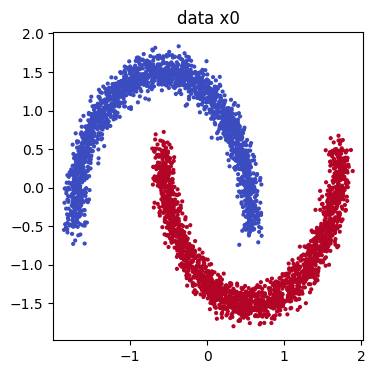

In [4]:
def sample_data(n):
    X, y = make_moons(n_samples=n, noise=0.06)
    X = (X - X.mean(0)) / X.std(0)                 # standardise to ~N(0,1) scale
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

X, y = sample_data(4000)
plt.figure(figsize=(4, 4))
plt.scatter(X[:, 0], X[:, 1], s=4, c=y, cmap="coolwarm"); plt.title("data x0"); plt.axis("equal"); plt.show()

## Part 1 · Forward process & schedule (15 min)

The forward process gradually turns data into noise. We need a **noise schedule** `ᾱ_t` (abar) that goes from ≈1 (no noise) at t=0 to ≈0 (pure noise) at t=T. Implement the **cosine schedule** (Nichol & Dhariwal, 2021), which keeps more signal in the middle than a linear one.

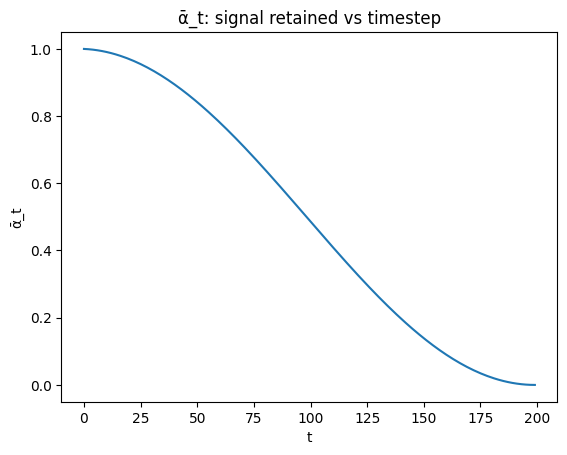

In [5]:
T = 200

def cosine_schedule(T, s=0.008):
    t = torch.linspace(0, T, T + 1) / T
    f = torch.cos((t + s) / (1 + s) * torch.pi / 2) ** 2
    abar = (f / f[0])[1:]                          # drop t=0 entry, normalise so abar[0] ~ 1
    alphas = torch.empty(T)
    alphas[0] = abar[0]                            # first alpha = abar[0]
    alphas[1:] = abar[1:] / abar[:-1]              # alpha_t = abar_t / abar_{t-1}
    betas = (1 - alphas).clamp(0, 0.999)           # avoid beta = 1 at the very last step
    alphas = 1 - betas                             # recompute so that everything is consistent
    abar = torch.cumprod(alphas, dim=0)
    return betas, alphas, abar

betas, alphas, abar = cosine_schedule(T)
assert abs(abar[0] - 1) < 0.05 and abar[-1] < 0.05
plt.plot(abar); plt.title("ᾱ_t: signal retained vs timestep"); plt.xlabel("t"); plt.ylabel("ᾱ_t"); plt.show()

The key identity lets us jump to any noise level in one shot:

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\; \varepsilon,\qquad \varepsilon\sim\mathcal N(0,I)$$

Implement `q_sample`, then visualise the same batch of moons at increasing t.

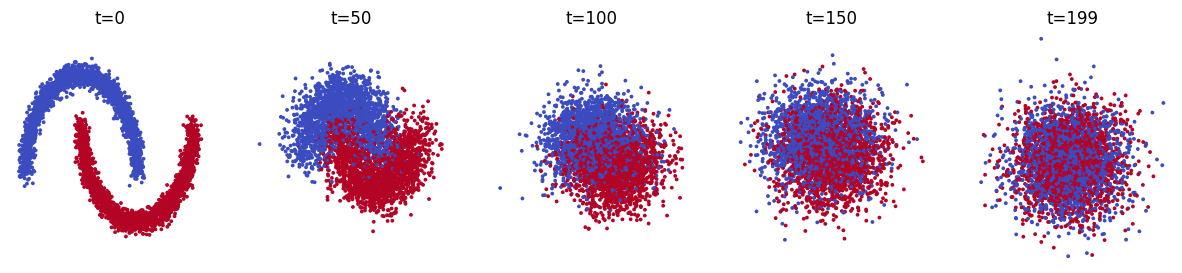

In [6]:
def q_sample(x0, t, noise):
    """Add t steps of noise to x0 in one shot. t is a LongTensor of shape (B,).
    x_t = sqrt(abar[t]) * x0 + sqrt(1 - abar[t]) * noise   (broadcast over the 2 dims)."""
    ab = abar.to(x0.device)[t.to(x0.device)].unsqueeze(1)      # (B, 1) -> broadcasts over the 2 coordinates
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, tt in zip(axes, [0, 50, 100, 150, 199]):
    tb = torch.full((len(X),), tt, dtype=torch.long)
    xt = q_sample(X, tb, torch.randn_like(X))
    ax.scatter(xt[:, 0], xt[:, 1], s=3, c=y, cmap="coolwarm"); ax.set_title(f"t={tt}"); ax.axis("equal"); ax.axis("off")
plt.show()

❓ **Q1.** At which t do the two moons stop being distinguishable? Replace the cosine schedule with a **linear** one Note that the classic values `betas = linspace(1e-4, 0.02, T)` were designed for **T = 1000**; with our T = 200 they must be scaled by 1000/T, otherwise the process never reaches pure noise and re-plot `ᾱ_t`. Which schedule destroys the structure sooner? Why might keeping signal longer help training?

✏️ **Resposta Q1.**

Com o schedule coseno as luas começam a perder a forma por volta de t=50, mas as duas classes ainda se distinguem em t=100 (uma mancha azul em cima e outra vermelha em baixo). Só perto de t=150 é que ficam misturadas, e em t=199 já é ruído puro. Com o linear (escalado) isto acontece bem mais cedo: em t=100 já está tudo misturado. Em números, o ᾱ do linear desce abaixo de 0,5 em t=51 e o do coseno só em t=99; abaixo de 0,1 é em t=94 contra t=158. Ou seja, o linear destrói a estrutura primeiro e passa o último terço dos passos (a partir de t≈133, com ᾱ<0,01) praticamente só com ruído. Testei também o linear sem escalar e o ᾱ final fica em 0,13, o que quer dizer que nunca chega a ruído puro, e isso é um problema porque a amostragem começa em N(0, I).

Manter o sinal mais tempo ajuda no treino porque o modelo só aprende alguma coisa útil quando o x_t ainda tem informação sobre o x₀. Quando é quase só ruído, prever o ruído é trivial (é praticamente o próprio x_t). Como o t é sorteado de forma uniforme, com o coseno há mais passos de treino em níveis de ruído que realmente ensinam algo.

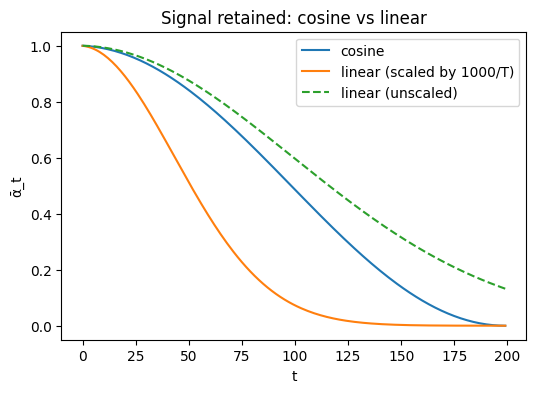

                          ᾱ<0.5    ᾱ<0.1   ᾱ<0.01     ᾱ[T-1]
cosine                       99      158      187   6.07e-08
linear (scaled)              51       94      133   3.03e-05
linear (unscaled)           117     None     None   1.32e-01


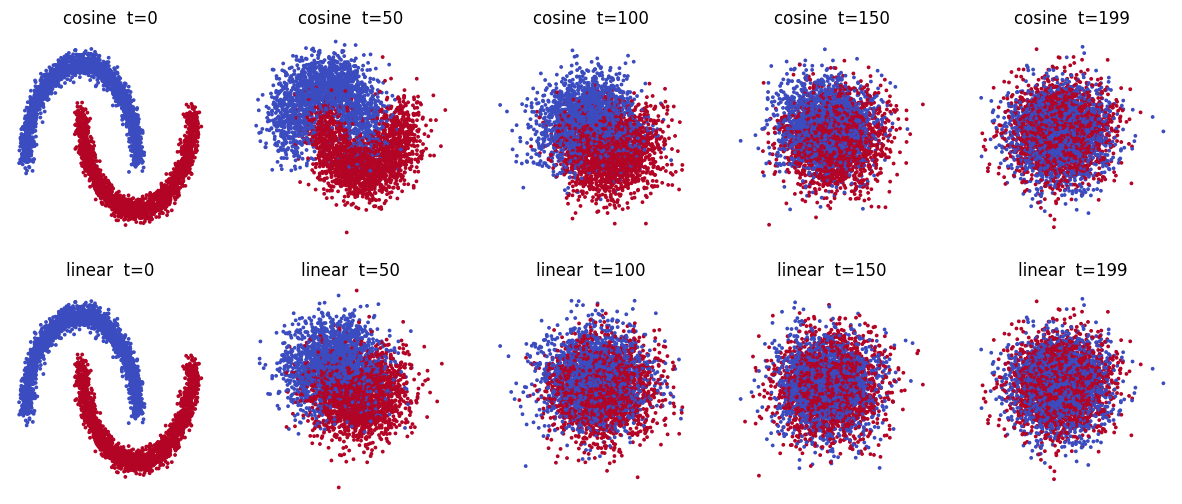

In [7]:
# Q1 · cosine vs linear schedule
# 1. Linear schedule. The classic values were designed for T = 1000, so for T = 200 we scale them by 1000/T.
betas_lin = torch.linspace(1e-4 * 1000 / T, 0.02 * 1000 / T, T)
abar_lin = torch.cumprod(1 - betas_lin, dim=0)

# (optional) the UNSCALED linear schedule: what goes wrong?
betas_raw = torch.linspace(1e-4, 0.02, T)
abar_raw = torch.cumprod(1 - betas_raw, dim=0)

# 2. Plot the three curves
plt.figure(figsize=(6, 4))
plt.plot(abar, label="cosine")
plt.plot(abar_lin, label="linear (scaled by 1000/T)")
plt.plot(abar_raw, "--", label="linear (unscaled)")
plt.xlabel("t"); plt.ylabel("ᾱ_t"); plt.title("Signal retained: cosine vs linear"); plt.legend(); plt.show()

def first_below(ab, thr):
    idx = (ab < thr).nonzero()
    return int(idx[0]) if len(idx) else None

print(f"{'':22s} {'ᾱ<0.5':>8s} {'ᾱ<0.1':>8s} {'ᾱ<0.01':>8s} {'ᾱ[T-1]':>10s}")
for name, ab_ in [("cosine", abar), ("linear (scaled)", abar_lin), ("linear (unscaled)", abar_raw)]:
    print(f"{name:22s} {str(first_below(ab_, .5)):>8s} {str(first_below(ab_, .1)):>8s} "
          f"{str(first_below(ab_, .01)):>8s} {ab_[-1].item():>10.2e}")

# 3. Same 5-panel plot with the linear schedule (second row) vs cosine (first row)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for j, tt in enumerate([0, 50, 100, 150, 199]):
    noise = torch.randn_like(X)
    xt_cos = q_sample(X, torch.full((len(X),), tt, dtype=torch.long), noise)
    xt_lin = abar_lin[tt].sqrt() * X + (1 - abar_lin[tt]).sqrt() * noise
    for row, (xt, nm) in enumerate([(xt_cos, "cosine"), (xt_lin, "linear")]):
        ax = axes[row, j]
        ax.scatter(xt[:, 0], xt[:, 1], s=3, c=y, cmap="coolwarm")
        ax.set_title(f"{nm}  t={tt}"); ax.axis("equal"); ax.axis("off")
plt.show()

## Part 2 · Train a denoiser (20 min)

The network takes a noisy point `x_t` and the timestep `t`, and predicts the **noise** that was added. We give it `t` through a small sinusoidal embedding (same idea as positional encodings).

In [8]:
def time_embedding(t, dim=32):
    """Map integer timesteps to a smooth vector (sinusoidal)."""
    t = t.float().unsqueeze(1)
    freqs = torch.exp(torch.linspace(0, np.log(1000), dim // 2, device=t.device))
    ang = t * freqs.unsqueeze(0)
    return torch.cat([ang.sin(), ang.cos()], dim=1)

class Denoiser(nn.Module):
    def __init__(self, hid=128, tdim=32, n_classes=0):
        super().__init__()
        self.tdim = tdim
        self.n_classes = n_classes
        if n_classes:
            self.cls_emb = nn.Embedding(n_classes + 1, tdim)   # +1 = the "null"/unconditional label
        in_dim = 2 + tdim + (tdim if n_classes else 0)
        self.net = nn.Sequential(nn.Linear(in_dim, hid), nn.SiLU(),
                                 nn.Linear(hid, hid), nn.SiLU(),
                                 nn.Linear(hid, hid), nn.SiLU(),
                                 nn.Linear(hid, 2))

    def forward(self, x, t, c=None):
        h = [x, time_embedding(t, self.tdim)]
        if self.n_classes:
            h.append(self.cls_emb(c))
        return self.net(torch.cat(h, dim=1))

print(sum(p.numel() for p in Denoiser().parameters()), "parameters")

37762 parameters


The training loss is exactly the one from the lecture: sample a random t, make `x_t`, and regress the predicted noise onto the true noise. Fill the loss.

step 0: loss 1.051
step 500: loss 0.472
step 1000: loss 0.443
step 1500: loss 0.405
step 2000: loss 0.397
step 2500: loss 0.406


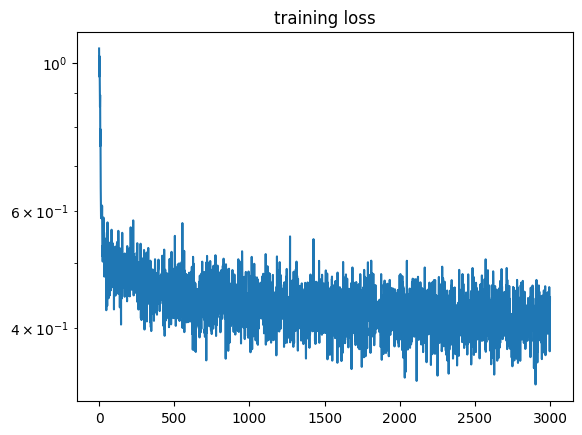

In [9]:
def diffusion_loss(model, x0, c=None):
    B = x0.shape[0]
    t = torch.randint(0, T, (B,), device=x0.device)
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)                                  # noisy input
    pred = model(xt, t) if c is None else model(xt, t, c)        # predicted noise
    return ((pred - noise) ** 2).mean()                          # MSE between predicted and true noise

model = Denoiser().to(device)
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
Xd = X.to(device)
losses = []
for step in range(3000):
    idx = torch.randint(0, len(Xd), (512,), device=device)
    loss = diffusion_loss(model, Xd[idx])
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
    if step % 500 == 0: print(f"step {step}: loss {loss.item():.3f}")
plt.plot(losses); plt.title("training loss"); plt.yscale("log"); plt.show()

❓ **Q2.** The loss plateaus well above zero and never reaches it. Why *should* it be impossible to drive this loss to 0, even with a perfect model? (Hint: for a given `x_t`, is the noise that produced it unique?)

✏️ **Resposta Q2.** A rede não consegue saber qual foi exatamente o ruído que se juntou. Para o mesmo x_t há muitos pares (x₀, ε) que dão o mesmo resultado: um ponto entre as duas luas pode ter vindo de vários pontos originais, cada um com o seu ruído. Por isso o melhor que o modelo pode fazer é prever o ruído médio dado x_t, e o erro dessa previsão (a variância do ruído condicionada a x_t) nunca é zero. Na minha execução a loss desceu de cerca de 1,05 para um patamar à volta de 0,40 e ficou por aí. Esse patamar não quer dizer que o modelo esteja mal treinado, é um limite do próprio problema. É maior para t pequenos (x_t é quase x₀ e é difícil saber o que é ruído) e menor para t grandes (x_t é quase só o ruído).

## Part 3 · Sampling: DDPM vs DDIM (20 min)

To generate, start from pure noise and walk the reverse process. First **DDPM**: at each step, use the predicted noise to estimate the slightly-less-noisy point, and add a little fresh noise (except at the last step).

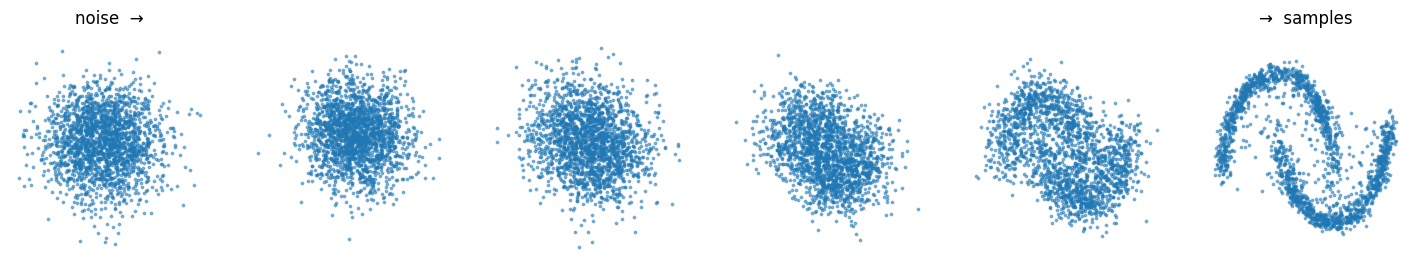

In [10]:
@torch.no_grad()
def ddpm_sample(model, n=2000, c=None):
    x = torch.randn(n, 2, device=device)
    traj = [x.cpu().clone()]
    for ti in reversed(range(T)):
        t = torch.full((n,), ti, dtype=torch.long, device=device)
        eps = model(x, t, c) if c is not None else model(x, t)
        b, a, ab = betas[ti], alphas[ti], abar[ti]
        mean = (x - (b / (1 - ab).sqrt()) * eps) / a.sqrt()
        x = mean + (b.sqrt() * torch.randn_like(x) if ti > 0 else 0)
        if ti % 40 == 0: traj.append(x.cpu().clone())
    return x.cpu(), traj

samples, traj = ddpm_sample(model)
fig, axes = plt.subplots(1, len(traj), figsize=(3 * len(traj), 3))
for ax, xt in zip(axes, traj):
    ax.scatter(xt[:, 0], xt[:, 1], s=3, alpha=0.5); ax.axis("equal"); ax.axis("off")
axes[0].set_title("noise  →"); axes[-1].set_title("→  samples"); plt.show()

Now **DDIM**: deterministic, and it can skip timesteps. Implement one DDIM step and a strided schedule, then compare quality at 5, 10, 20 and 100 steps.

> **Important · clip the x₀ estimate.** With the cosine schedule, ᾱ at the last timestep is ≈ 6×10⁻⁸, so the first DDIM step divides by √ᾱ ≈ 2.5×10⁻⁴ and multiplies any error in ε̂ by about 4 000. DDPM does not have this problem because it never estimates x₀ explicitly. Since our data are standardised, clipping x₀ to [−3, 3] fixes it (this is `clip_sample` in the `diffusers` library).

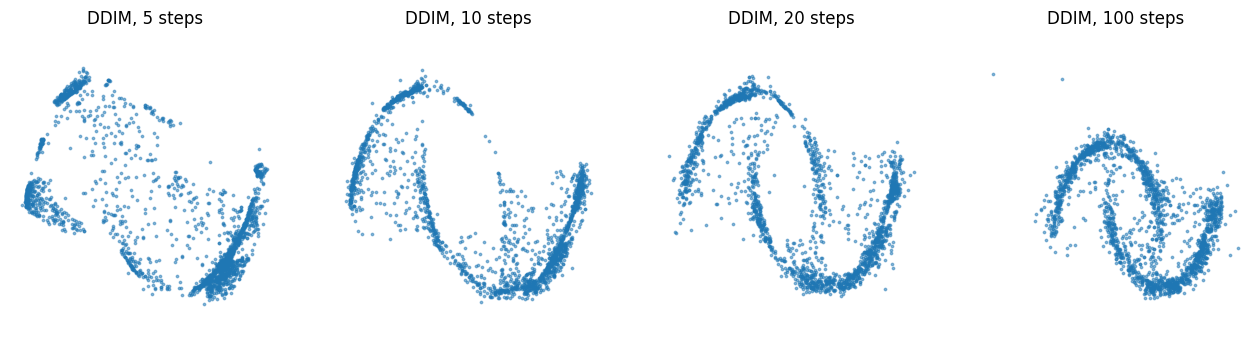

In [11]:
@torch.no_grad()
def ddim_sample(model, n=2000, steps=20, c=None):
    x = torch.randn(n, 2, device=device)
    ts = torch.linspace(T - 1, 0, steps).round().long()     # strided timesteps, high -> low
    for i, ti in enumerate(ts):
        t = torch.full((n,), ti, dtype=torch.long, device=device)
        eps = model(x, t, c) if c is not None else model(x, t)
        ab_t = abar[ti]
        ab_prev = abar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        x0 = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()            # predict x0 from x and eps
        x0 = x0.clamp(-3, 3)                                         # clip the estimate (see note above)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps         # deterministic step to the previous level
    return x.cpu()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, k in zip(axes, [5, 10, 20, 100]):
    s = ddim_sample(model, steps=k)
    ax.scatter(s[:, 0], s[:, 1], s=3, alpha=0.5); ax.set_title(f"DDIM, {k} steps"); ax.axis("equal"); ax.axis("off")
plt.show()

❓ **Q3.** Roughly how few DDIM steps still give clean moons? DDPM used all 200 steps and adds randomness; DDIM is deterministic. Time both for the same sample count (cell below). What is the practical trade-off, and how does it connect to the "quality–speed dial" from the lecture?

In [12]:
# Q3 · timing DDPM vs DDIM for the same number of samples
import time

def timed(fn):
    """Wall-clock time of fn(), waiting for the GPU to finish."""
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter(); fn()
    if device == "cuda": torch.cuda.synchronize()
    return time.perf_counter() - t0

timed(lambda: ddim_sample(model, n=2000, steps=5))                 # warm-up (excludes one-off start-up costs)

timing = {}
t_ddpm = timed(lambda: ddpm_sample(model, n=2000))
timing["DDPM (200)"] = t_ddpm
print(f"DDPM, 200 steps : {t_ddpm:7.3f} s")
for k in [5, 10, 20, 50]:
    t_k = timed(lambda: ddim_sample(model, n=2000, steps=k))
    timing[f"DDIM ({k})"] = t_k
    print(f"DDIM, {k:3d} steps: {t_k:7.3f} s   -> {t_ddpm / t_k:5.1f}x faster than DDPM")

DDPM, 200 steps :   0.116 s
DDIM,   5 steps:   0.003 s   ->  34.2x faster than DDPM
DDIM,  10 steps:   0.006 s   ->  20.0x faster than DDPM
DDIM,  20 steps:   0.011 s   ->  10.3x faster than DDPM
DDIM,  50 steps:   0.028 s   ->   4.2x faster than DDPM


In [13]:
# Q3 (extra) · how many DDIM steps are "enough"?  Quantify it instead of eyeballing the plots.
# Metric: mean distance from each generated point to its nearest point of the dataset
# (lower = closer to the moons). The baseline is a fresh batch of REAL data measured the same way.
def nn_dist(s, ref=X):
    return torch.cdist(s, ref).min(dim=1).values.mean().item()

baseline = nn_dist(sample_data(2000)[0])
quality = {"DDPM (200)": nn_dist(ddpm_sample(model, n=2000)[0])}
for k in [2, 3, 5, 10, 20, 50, 100]:
    quality[f"DDIM ({k})"] = nn_dist(ddim_sample(model, n=2000, steps=k))

print(f"baseline (real data)   : {baseline:.4f}")
for name, v in quality.items():
    print(f"{name:12s}: {v:.4f}   ({v / baseline:4.1f}x baseline)")

# "clean moons" = within 1.5x of the quality of the full 200-step DDPM sampler
# (the reference for THIS small model; even DDPM is ~1.6x the real-data baseline, so a threshold
#  relative to the real data would never be met)
ref_ddpm = quality["DDPM (200)"]
clean_steps = next((k for k in [2, 3, 5, 10, 20, 50, 100] if quality[f"DDIM ({k})"] <= 1.5 * ref_ddpm), None)
print(f"\nsmallest DDIM step count within 1.5x of DDPM quality ({1.5 * ref_ddpm:.4f}): {clean_steps}")

baseline (real data)   : 0.0165
DDPM (200)  : 0.0267   ( 1.6x baseline)
DDIM (2)    : 2.3256   (141.0x baseline)
DDIM (3)    : 0.1143   ( 6.9x baseline)
DDIM (5)    : 0.0457   ( 2.8x baseline)
DDIM (10)   : 0.0311   ( 1.9x baseline)
DDIM (20)   : 0.0286   ( 1.7x baseline)
DDIM (50)   : 0.0305   ( 1.9x baseline)
DDIM (100)  : 0.0338   ( 2.0x baseline)

smallest DDIM step count within 1.5x of DDPM quality (0.0401): 10


✏️ **Resposta Q3.**

Pela tabela da distância média à lua mais próxima (dados reais 0,017; DDPM 0,027), com 2 passos o DDIM falha por completo (2,33), com 3 dá 0,11, com 5 dá 0,046 e a partir de 10 passos fica por volta de 0,03, ao nível do DDPM (0,031 com 10, 0,029 com 20, 0,031 com 50 e 0,034 com 100). Por isso diria que 10 passos já chegam (é o valor que o `clean_steps` dá) e que 20 é mais seguro. Com 5 passos ainda se veem muitos pontos espalhados entre as luas. Depois dos 20 passos já não melhora, e julgo que o que limita é o modelo ser pequeno e pouco treinado, porque mesmo com 100 passos ainda aparecem alguns pontos perdidos.

Quanto ao tempo (2000 amostras, GPU): o DDPM demorou 0,116 s e o DDIM com 5, 10, 20 e 50 passos demorou 0,003 s, 0,006 s, 0,011 s e 0,028 s, ou seja 34×, 20×, 10× e 4× mais rápido. Fica muito perto de 200/passos, o que faz sentido porque o custo é basicamente o número de vezes que se chama a rede.

O compromisso é o habitual: menos passos é mais rápido, mas a qualidade piora porque o processo inverso é aproximado de forma mais grosseira. O DDIM também é determinístico (o mesmo ruído dá sempre a mesma amostra), enquanto o DDPM mete ruído novo em cada passo. O número de passos é o "quality–speed dial" da aula: com o mesmo modelo treinado escolhe-se quanta computação gastar, tal como o `num_inference_steps` do Stable Diffusion.

## Part 4 · Conditioning & classifier-free guidance (20 min)

Now we condition on the **moon label**. During training we sometimes drop the label (replace it with a "null" class) so the same model learns both the conditional and the unconditional noise — that is what makes classifier-free guidance possible.

In [14]:
NULL = 2   # the null/unconditional label (classes are 0 and 1)

def cond_loss(model, x0, c, p_drop=0.1):
    B = x0.shape[0]
    t = torch.randint(0, T, (B,), device=x0.device)
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)
    c_in = c.clone()
    drop = torch.rand(B, device=x0.device) < p_drop
    c_in[drop] = NULL                                  # randomly drop the label
    return ((model(xt, t, c_in) - noise) ** 2).mean()

cmodel = Denoiser(n_classes=2).to(device)
opt = torch.optim.Adam(cmodel.parameters(), lr=2e-3)
Xd, yd = X.to(device), y.to(device)
for step in range(4000):
    idx = torch.randint(0, len(Xd), (512,), device=device)
    loss = cond_loss(cmodel, Xd[idx], yd[idx])
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 1000 == 0: print(f"step {step}: loss {loss.item():.3f}")
print("done")

step 0: loss 1.040
step 1000: loss 0.290
step 2000: loss 0.339
step 3000: loss 0.383
done


Classifier-free guidance combines the conditional and unconditional predictions:

$$\hat\varepsilon = \varepsilon_\varnothing + w\,(\varepsilon_c - \varepsilon_\varnothing)$$

Implement a guided DDIM sampler, then sweep the guidance scale `w`.

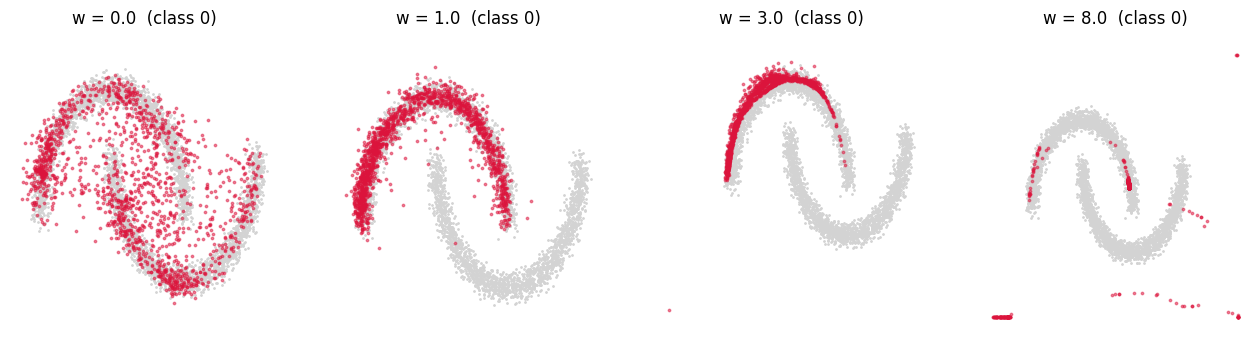

In [15]:
@torch.no_grad()
def guided_sample(model, label, n=1500, steps=50, w=3.0):
    x = torch.randn(n, 2, device=device)
    c = torch.full((n,), label, dtype=torch.long, device=device)
    null = torch.full((n,), NULL, dtype=torch.long, device=device)
    ts = torch.linspace(T - 1, 0, steps).round().long()
    for i, ti in enumerate(ts):
        t = torch.full((n,), ti, dtype=torch.long, device=device)
        eps_c = model(x, t, c)       # conditional prediction
        eps_u = model(x, t, null)    # unconditional prediction
        eps = eps_u + w * (eps_c - eps_u)        # classifier-free guidance
        ab_t = abar[ti]; ab_prev = abar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        x0 = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        x0 = x0.clamp(-3, 3)                 # same fix as in ddim_sample
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    return x.cpu()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, w in zip(axes, [0.0, 1.0, 3.0, 8.0]):
    ax.scatter(X[:, 0], X[:, 1], s=1, c="lightgray")      # data, for reference
    s = guided_sample(cmodel, label=0, w=w)
    ax.scatter(s[:, 0], s[:, 1], s=3, alpha=0.5, c="crimson")
    ax.set_title(f"w = {w}  (class 0)"); ax.axis("equal"); ax.axis("off")
plt.show()

reference real class-0 spread: 0.724

    w   spread     dist  on_cls0
  0.0    0.912   0.0621     0.53
  1.0    0.737   0.0208     1.00
  3.0    0.660   0.0253     1.00
  8.0    0.852   0.2146     0.97
 15.0    0.642   1.2680     0.63


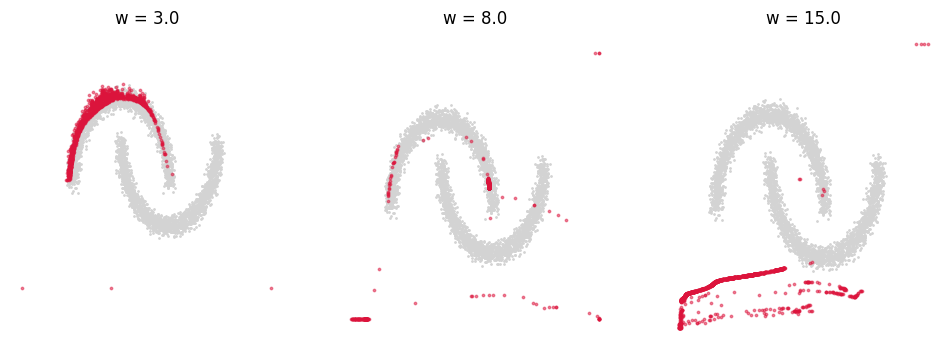

In [16]:
# Q4 (extra) · measure diversity and fidelity vs guidance scale, for class 0
# - spread : std of the samples (how much of the moon is covered; the real class-0 moon is the reference)
# - dist   : mean distance to the nearest REAL class-0 point (fidelity; lower = closer to the moon)
# - on_cls0: fraction of samples whose nearest real point belongs to class 0
X0 = X[y == 0]
ref_spread = X0.std(0).mean().item()
print(f"reference real class-0 spread: {ref_spread:.3f}\n")
print(f"{'w':>5s} {'spread':>8s} {'dist':>8s} {'on_cls0':>8s}")
for w in [0.0, 1.0, 3.0, 8.0, 15.0]:
    s = guided_sample(cmodel, label=0, w=w)
    d = torch.cdist(s, X)                                   # distance to every real point
    nn_idx = d.argmin(dim=1)
    print(f"{w:5.1f} {s.std(0).mean().item():8.3f} {d.min(1).values.mean().item():8.4f} {(y[nn_idx] == 0).float().mean().item():8.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, w in zip(axes, [3.0, 8.0, 15.0]):
    ax.scatter(X[:, 0], X[:, 1], s=1, c="lightgray")
    s = guided_sample(cmodel, label=0, w=w)
    ax.scatter(s[:, 0], s[:, 1], s=3, alpha=0.5, c="crimson"); ax.set_title(f"w = {w}"); ax.axis("equal"); ax.axis("off")
plt.show()

❓ **Q4.** At `w=0` you sample from *both* moons; by `w=3` the samples concentrate on class 0. What happens to **diversity** as `w` grows past 8 — do the points spread along the whole moon, or collapse? Relate this to "over-saturated / fried" images at high guidance in real text-to-image models.

✏️ **Resposta Q4.** Valores que medi para a classe 0 (a dispersão real da lua é 0,72):

| w | dispersão | distância à lua real | % junto da classe 0 |
|---|---|---|---|
| 0 | 0,91 | 0,062 | 53 % |
| 1 | 0,74 | 0,021 | 100 % |
| 3 | 0,66 | 0,025 | 100 % |
| 8 | 0,85 | 0,215 | 97 % |
| 15 | 0,64 | 1,268 | 63 % |

Com w=0 saem as duas luas (só 53 % dos pontos ficam perto da classe 0). Com w=1 ficam todos na classe 0, com a melhor fidelidade e uma dispersão parecida com a real. Com w=3 continuam na classe certa, mas juntam-se mais na zona de cima da lua e cobrem pior as pontas, ou seja, já se perde diversidade. A partir de w=8 deixam de se espalhar pela lua e saem da zona dos dados: a distância sobe para 0,21 (w=8) e 1,27 (w=15), e nos gráficos vêem-se pontos nos cantos, presos ao limite do clip (±3). A dispersão de 0,85 em w=8 engana, porque sobe por causa desses pontos fora da lua e não por haver mais diversidade. Acho que isto acontece porque ε_u + w(ε_c − ε_u) com w grande extrapola muito para lá da previsão condicional.

Nos modelos reais é o mesmo efeito. No B1 vê-se que com guidance 15 a imagem fica com contraste e saturação exagerados (o aspeto "queimado"), enquanto com guidance 1 quase não segue o prompt. Por isso os valores normalmente usados (5 a 8) são um compromisso entre diversidade e seguir o prompt.

## Part 5 · CLIP: zero-shot & retrieval (25 min)

Switch to multimodality. **CLIP** maps images and text into one shared space. We load a small pretrained CLIP and use it with **no fine-tuning**.

In [17]:
import open_clip
clip_model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")
tokenizer = open_clip.get_tokenizer("ViT-B-32")
clip_model = clip_model.to(device).eval()

def embed_texts(prompts):
    toks = tokenizer(prompts).to(device)
    with torch.no_grad():
        f = clip_model.encode_text(toks)
    return f / f.norm(dim=-1, keepdim=True)

def embed_images(pil_images):
    batch = torch.stack([preprocess(im) for im in pil_images]).to(device)
    with torch.no_grad():
        f = clip_model.encode_image(batch)
    return f / f.norm(dim=-1, keepdim=True)
print("CLIP loaded")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

CLIP loaded


We need a few images. The next cell downloads a handful of varied photos from Wikimedia Commons.

> **⚠️ Plan B · if the classroom network blocks Wikimedia**
>
> If the next cell prints `skip` for (almost) every image (or stops with the message *“No images loaded”*), the safest option is to use local images:
>
> 1. Create a folder called `imagens` in the Colab file panel (📁 icon on the left → right-click → *New folder*).
> 2. Drag about five photos into it. Each file name becomes the label, so use names such as `dog.jpg`, `cat.jpg`, `car.jpg`, `pizza.jpg`, `beach.jpg`.
> 3. Run the cell again.
>
> Files uploaded to Colab are deleted when the session restarts; if that happens, repeat steps 1 and 2.

loaded ['dog', 'cat', 'car', 'pizza', 'beach'] | extra ['dogs']


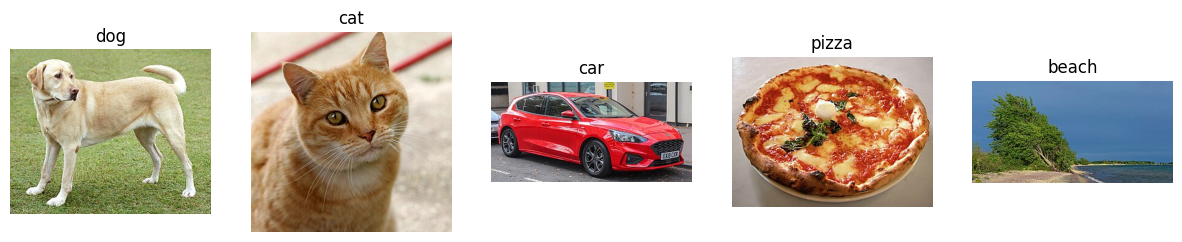

In [18]:
from PIL import Image
import urllib.request, urllib.parse, io, os, glob

# Wikimedia Commons files (several candidates per label, in case one is renamed or removed).
# We request a 330 px width through Special:FilePath, because Wikimedia restricts
# thumbnails with non-standard widths (such as 320 px).
FILES = {
    "dog":   ["YellowLabradorLooking_new.jpg"],                       # ONE dog (used in Part 6)
    "cat":   ["Cat03.jpg"],
    "car":   ["2018_Ford_Focus_ST-Line_TDCi_1.5_Front.jpg",
              "2017_Toyota_Camry_(ASV70R)_SX_sedan_(2018-11-02)_01.jpg"],
    "pizza": ["Eq_it-na_pizza-margherita_sep2005_sml.jpg"],
    "beach": ["Big_Sandy_Bay_beach.jpg",
              "Gentle_waves_come_in_at_a_sandy_beach.JPG"],
}
EXTRA = {"dogs": ["Collage_of_Nine_Dogs.jpg"]}                         # MANY dogs (Part 6 only)

# Wikimedia requires an identifiable User-Agent; a bare "Mozilla/5.0" may be blocked.
HEADERS = {"User-Agent": "PL9-CLIP-lab/1.0 (teaching notebook; python-urllib)"}

def download(fname, width=330):
    url = ("https://commons.wikimedia.org/wiki/Special:FilePath/"
           + urllib.parse.quote(fname) + f"?width={width}")
    req = urllib.request.Request(url, headers=HEADERS)
    return Image.open(io.BytesIO(urllib.request.urlopen(req, timeout=15).read())).convert("RGB")

def load(files):
    imgs, nms = [], []
    for name, candidates in files.items():
        for fname in candidates:
            try:
                imgs.append(download(fname)); nms.append(name); break
            except Exception as e:
                print("skip", name, fname, "->", e)
    return imgs, nms

images, names = load(FILES)
extra_images, extra_names = load(EXTRA)

# Plan B: images uploaded by hand to the Colab folder "imagens/" (file name = label)
if len(images) < 3:
    for path in sorted(glob.glob("imagens/*")):
        try:
            images.append(Image.open(path).convert("RGB"))
            names.append(os.path.splitext(os.path.basename(path))[0])
        except Exception as e:
            print("skip", path, "->", e)

assert images, ("No images loaded. Create the folder 'imagens/' in Colab, upload a few photos "
                "to it (e.g. dog.jpg, cat.jpg, pizza.jpg) and run this cell again.")
print("loaded", names, "| extra", extra_names)

fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 3))
for ax, im, nm in zip(np.atleast_1d(axes), images, names):
    ax.imshow(im); ax.set_title(nm); ax.axis("off")
plt.show()

### Zero-shot classification

Build label prompts, embed images and texts, and classify by cosine similarity through a softmax. Fill `zero_shot`.

In [19]:
LABELS = ["a dog", "a cat", "a car", "a pizza", "a beach", "a laptop", "a mountain"]

def zero_shot(pil_images, labels):
    img = embed_images(pil_images)           # (N, d), already L2-normalised
    txt = embed_texts(labels)                # (L, d), already L2-normalised
    sims = img @ txt.T                       # cosine similarities, (N, L)
    logits = clip_model.logit_scale.exp() * sims     # temperature ~ 0.01  (scale ~ 100)
    return logits.softmax(dim=-1).cpu()      # (N, L) probabilities

probs = zero_shot(images, LABELS)
for i, nm in enumerate(names):
    k = probs[i].argmax().item()
    print(f"{nm:6s} -> {LABELS[k]:10s}  ({probs[i, k]:.2f})")

dog    -> a dog       (1.00)
cat    -> a cat       (1.00)
car    -> a car       (1.00)
pizza  -> a pizza     (1.00)
beach  -> a beach     (1.00)


❓ **Q5.** Zero-shot means CLIP was never trained on these exact labels. Did it get them right? Now rewrite the labels as bare words (`"dog"` not `"a dog"`) or add the classic prompt template (`"a photo of a dog"`). Does **prompt phrasing** change the result? This is *prompt engineering for vision*.

In [20]:
# Q5 · does prompt phrasing change the result?
CLASSES = ["dog", "cat", "car", "pizza", "beach", "laptop", "mountain"]
TEMPLATES = {"bare word": "{}", "a/an": "a {}", "a photo of": "a photo of a {}"}

img_emb = embed_images(images)                          # computed once
scale = clip_model.logit_scale.exp()
clip_results = {}
for tname, tpl in TEMPLATES.items():
    prompts = [tpl.format(c) for c in CLASSES]
    txt = embed_texts(prompts)
    sims = img_emb @ txt.T                              # (N, L)
    probs_t = (scale * sims).softmax(dim=-1).cpu()
    print(f"\n=== template: {tname!r}  (e.g. {prompts[0]!r}) ===")
    correct = 0
    for i, nm in enumerate(names):
        k = probs_t[i].argmax().item()
        true_k = CLASSES.index(nm) if nm in CLASSES else None
        sim_true = f"{sims[i, true_k].item():.3f}" if true_k is not None else "  n/a"
        ok = (k == true_k)
        correct += ok
        print(f"  {nm:6s} -> {CLASSES[k]:9s} p={probs_t[i, k]:.2f}  cos(img, true label)={sim_true}  {'OK' if ok else 'WRONG'}")
    clip_results[tname] = correct
    print(f"  accuracy: {correct}/{len(names)}")
print("\nsummary:", clip_results)


=== template: 'bare word'  (e.g. 'dog') ===
  dog    -> dog       p=1.00  cos(img, true label)=0.265  OK
  cat    -> cat       p=1.00  cos(img, true label)=0.268  OK
  car    -> car       p=0.98  cos(img, true label)=0.257  OK
  pizza  -> pizza     p=1.00  cos(img, true label)=0.290  OK
  beach  -> beach     p=1.00  cos(img, true label)=0.258  OK
  accuracy: 5/5

=== template: 'a/an'  (e.g. 'a dog') ===
  dog    -> dog       p=1.00  cos(img, true label)=0.275  OK
  cat    -> cat       p=1.00  cos(img, true label)=0.292  OK
  car    -> car       p=1.00  cos(img, true label)=0.270  OK
  pizza  -> pizza     p=1.00  cos(img, true label)=0.305  OK
  beach  -> beach     p=1.00  cos(img, true label)=0.270  OK
  accuracy: 5/5

=== template: 'a photo of'  (e.g. 'a photo of a dog') ===
  dog    -> dog       p=1.00  cos(img, true label)=0.287  OK
  cat    -> cat       p=1.00  cos(img, true label)=0.301  OK
  car    -> car       p=1.00  cos(img, true label)=0.290  OK
  pizza  -> pizza     p=1.00 

✏️ **Resposta Q5.** Acertou: 5/5 com os três tipos de prompt (palavra solta, "a X" e "a photo of a X"), com probabilidades de 1,00 quase sempre (a mais baixa foi 0,98, no carro com a palavra solta). O CLIP não foi treinado com estas etiquetas exatas, mas como aprendeu a ligar imagens a legendas, qualquer etiqueta pode ser tratada como uma legenda e comparada com a imagem.

A formulação não mudou a classe prevista nem as probabilidades (que estão saturadas, porque o logit_scale é cerca de 100 e as imagens são fáceis). Mudou um bocadinho a similaridade coseno com a etiqueta certa: média de 0,268 com a palavra solta, 0,282 com "a X" e 0,288 com "a photo of a X". O template clássico foi o melhor em média e a palavra solta o pior, embora não em todas as imagens (na pizza e na praia o "a X" ficou ligeiramente acima). As diferenças são pequenas porque são só 7 classes e as imagens são muito claras; o efeito do prompt engineering deve notar-se mais em classes ambíguas, que não testei.

### Image–text retrieval

Use the same embeddings the other way: given a text query, rank the images.

In [21]:
def search(query, pil_images, names):
    q = embed_texts([query])
    img = embed_images(pil_images)
    sims = (img @ q.T).squeeze(1)
    order = sims.argsort(descending=True)
    return [(names[i], sims[i].item()) for i in order]

for q in ["something you can eat", "a place to relax on holiday", "a furry animal"]:
    ranking = search(q, images, names)
    print(f"{q:32s} -> " + ", ".join(f"{n}({s:.2f})" for n, s in ranking[:3]))

something you can eat            -> pizza(0.18), cat(0.16), dog(0.12)
a place to relax on holiday      -> beach(0.20), pizza(0.10), car(0.08)
a furry animal                   -> cat(0.24), dog(0.21), car(0.16)


❓ **Q6.** The query "something you can eat" never contains the word *pizza*, yet it should rank pizza first. Why does CLIP handle this, where a keyword search (BM25 from PL7) would fail? Connect this to dense retrieval and to the role CLIP plays as the "eyes" of a VLM.

✏️ **Resposta Q6.** O CLIP compara significado e não palavras. Foi treinado de forma contrastiva com muitos milhões de pares imagem–legenda, para que uma imagem e a legenda que a descreve fiquem perto no mesmo espaço vetorial. "Something you can eat" fica perto da zona das imagens de comida, mesmo sem a palavra "pizza" aparecer. Na minha execução a pizza ficou em primeiro (0,18), à frente do gato (0,16) e do cão (0,12). A margem é pequena porque uma pergunta abstrata dá similaridades baixas, mas a ordem está certa, tal como nas outras consultas ("a place to relax on holiday" → beach com 0,20; "a furry animal" → cat com 0,24 e dog com 0,21).

O BM25 (PL7) só conta termos em comum entre a pergunta e o documento, por isso sem nenhuma palavra em comum a pontuação é zero (vocabulary mismatch) e, no caso das imagens, nem sequer há texto para indexar. O CLIP faz recuperação densa (bi-encoder) entre modalidades: calculam-se os embeddings uma vez e ordena-se por similaridade coseno. Dentro de um VLM, o codificador de imagem tipo CLIP faz de "olhos": transforma a imagem em embeddings alinhados com a linguagem, que um projetor entrega ao LLM como se fossem tokens.

## Part 6 · Probing a multimodal model (5 min)

CLIP judges *similarity* but cannot *reason*. Try to trip it up and see where the shared embedding is weak. We use two images: one with a single dog, and a collage with nine dogs.

In [22]:
# Counting, relations and negation are classic CLIP weaknesses.
# We compare an image with ONE dog and an image with MANY dogs.
tricky = ["a dog", "one dog", "two dogs", "many dogs", "no dog", "a cat", "a dog to the left of a cat"]
probe = {}
if "dog" in names:       probe["one dog (Labrador)"] = images[names.index("dog")]
if "dogs" in extra_names: probe["nine dogs (collage)"] = extra_images[extra_names.index("dogs")]
if not probe:            probe["first image"] = images[0]

txt = embed_texts(tricky)
for title, im in probe.items():
    sims = (embed_images([im]) @ txt.T).squeeze(0)
    print(f"── image: {title} ──")
    for p, s in sorted(zip(tricky, sims.tolist()), key=lambda z: -z[1]):
        print(f"  {s:.3f}  {p}")

── image: one dog (Labrador) ──
  0.275  a dog
  0.235  one dog
  0.205  a dog to the left of a cat
  0.191  two dogs
  0.184  no dog
  0.177  many dogs
  0.146  a cat
── image: nine dogs (collage) ──
  0.288  many dogs
  0.240  a dog
  0.234  one dog
  0.212  two dogs
  0.185  a dog to the left of a cat
  0.175  no dog
  0.089  a cat


❓ **Q7.** Does CLIP reliably tell "one dog" from "two dogs", or "a dog" from "no dog"? Name one real task where this blind spot would cause a failure, and one architectural idea from the lecture (projector + LLM, native fusion) that could help.

✏️ **Resposta Q7.** Na imagem do cão sozinho a ordem foi: "a dog" 0,275, "one dog" 0,235, "a dog to the left of a cat" 0,205, "two dogs" 0,191, "no dog" 0,184, "many dogs" 0,177 e "a cat" 0,146. Na colagem dos 9 cães: "many dogs" 0,288, "a dog" 0,240, "one dog" 0,234, "two dogs" 0,212, "a dog to the left of a cat" 0,185, "no dog" 0,175 e "a cat" 0,089.

Não distingue de forma fiável. Há um sinal grosseiro de "um contra muitos" ("many dogs" fica em primeiro na colagem), mas contagem exata não: na colagem de 9 cães, "one dog" (0,234) fica acima de "two dogs" (0,212), e as diferenças são de poucos centésimos. Com a negação é pior: "no dog" dá 0,184 na foto do cão, acima de "a cat" (0,146), porque a frase menciona "dog" e o CLIP parece tratar o embedding como um saco de conceitos. O mesmo com a relação espacial: "a dog to the left of a cat" fica em terceiro numa foto sem gato nenhum. Faz sentido, porque as legendas da web raramente dizem quantos objetos há, o que não está na imagem ou onde estão as coisas.

Uma tarefa real onde isto falharia é a moderação ou pesquisa de "fotos sem pessoas", ou a segurança numa obra (distinguir um trabalhador com capacete de um sem capacete). Uma ideia da aula que ajudava é a arquitetura projetor + LLM (tipo LLaVA): o codificador dá embeddings por zonas da imagem, um projetor passa-os para o espaço de tokens do LLM e o LLM consegue raciocinar sobre eles (contar, negar, comparar), em vez de a imagem ficar reduzida a um único vetor. A fusão nativa (treinar logo com texto e imagem juntos) também ajudaria.

## Part 7 · Results & report (5 min)

### Report

1. **Diffusion:** o menor número de passos DDIM que ainda deu luas limpas foi 10 (fica a cerca de 1,2× a distância do DDPM com 200 passos; com 5 passos ainda há muitos pontos dispersos, com 3 é mau e com 2 falha por completo; de 20 em diante já não melhora). Tempos para 2000 amostras (GPU, na minha execução): DDPM com 200 passos 0,116 s; DDIM com 5, 10, 20 e 50 passos 0,003 s (34×), 0,006 s (20×), 0,011 s (10×) e 0,028 s (4×). O ganho é aproximadamente 200/passos.
2. **Guidance:** o guidance scale `w` troca diversidade por fidelidade à condição: com `w` maior as amostras são mais claramente da classe pedida mas menos variadas, e com `w` demasiado grande a extrapolação faz as amostras sair da zona dos dados (o equivalente às imagens "queimadas" dos modelos de texto para imagem).
3. **CLIP:** sucesso: o zero-shot acertou as 5 fotos (cão, gato, carro, pizza, praia) nos três templates, e a pesquisa texto→imagem pôs a pizza em primeiro com a consulta abstrata "something you can eat". Falha: contagem e negação ("no dog" deu 0,184 na foto de um cão, acima de "a cat" com 0,146, e na colagem de 9 cães "one dog" ficou à frente de "two dogs"). A formulação do prompt não mudou a classe prevista, só a similaridade coseno (média de 0,268 com a palavra solta, 0,282 com "a X" e 0,288 com "a photo of a X").
4. **Uma ligação entre as duas metades:** nos dois casos há um sinal de condição e a mesma ideia de guidance. Nos modelos de texto para imagem a condição é um embedding de texto tipo CLIP (o Stable Diffusion usa o codificador de texto do CLIP) e o classifier-free guidance da Parte 4 é o que obriga o desruidor a segui-lo. Os embeddings multimodais dizem o que gerar e a difusão trata de como gerar, e o guidance scale e o número de passos são os dois "botões" que explorámos (e confirmei no B1 com imagens reais).
5. **Respostas a Q1–Q7:** estão nas células ✏️ a seguir a cada pergunta. Em resumo:
   - Q1: o coseno mantém o sinal mais tempo (ᾱ<0,5 em t≈99 contra t≈51 no linear), por isso o linear destrói a estrutura mais cedo.
   - Q2: muitos pares (x₀, ε) dão o mesmo x_t, logo há um erro mínimo que não desaparece (a loss ficou por 0,40).
   - Q3: 10 a 20 passos DDIM chegam e o ganho de tempo é cerca de 200/passos.
   - Q4: com `w` maior há menos diversidade e, a partir de 3 a 8, as amostras saem da zona dos dados.
   - Q5: o zero-shot funciona (5/5) e a formulação muda a similaridade mas não a classe.
   - Q6: o CLIP compara significado num espaço partilhado, o BM25 precisa de palavras em comum.
   - Q7: o CLIP é fraco em contagem exata, negação e relações espaciais.

In [23]:
# Measured numbers for the report (run the cells above first)
print("== Diffusion ==")
try:
    print("smallest DDIM step count with clean moons:", clean_steps)
    for k, v in timing.items():
        print(f"  {k:12s} {v:7.3f} s   ({timing['DDPM (200)'] / v:5.1f}x vs DDPM)")
except NameError:
    print("run Part 3 first")
print("\n== CLIP zero-shot accuracy per template ==")
try:
    print(clip_results)
except NameError:
    print("run Part 5 first")

== Diffusion ==
smallest DDIM step count with clean moons: 10
  DDPM (200)     0.116 s   (  1.0x vs DDPM)
  DDIM (5)       0.003 s   ( 34.2x vs DDPM)
  DDIM (10)      0.006 s   ( 20.0x vs DDPM)
  DDIM (20)      0.011 s   ( 10.3x vs DDPM)
  DDIM (50)      0.028 s   (  4.2x vs DDPM)

== CLIP zero-shot accuracy per template ==
{'bare word': 5, 'a/an': 5, 'a photo of': 5}


## ★ Bonus (at home or for fast teams)

**B1 · Real image diffusion.** Use `diffusers` to run a pretrained latent diffusion model, and reproduce the Part 3 and Part 4 experiments on real images: sweep the number of inference steps and the guidance scale.

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

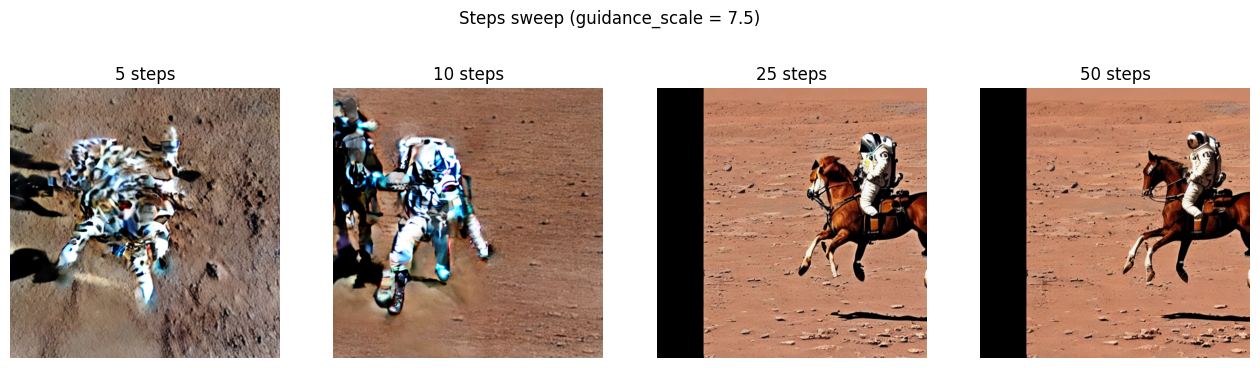

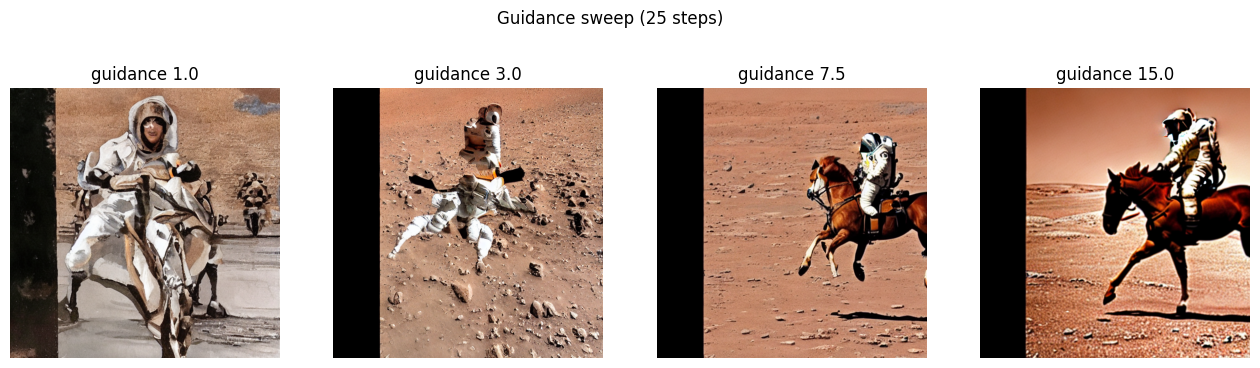

In [24]:
# B1 · real image diffusion with Stable Diffusion (needs a GPU; skipped otherwise)
if device != "cuda":
    print("No GPU available -> skipping B1 (Runtime > Change runtime type > GPU, then re-run).")
else:
    !pip -q install diffusers transformers accelerate safetensors
    from diffusers import StableDiffusionPipeline
    pipe = StableDiffusionPipeline.from_pretrained(
        "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16,
        safety_checker=None, requires_safety_checker=False).to("cuda")
    pipe.set_progress_bar_config(disable=True)
    prompt = "a photo of an astronaut riding a horse on mars"

    def gen(steps, gs):
        g = torch.Generator("cuda").manual_seed(0)          # same seed in every panel
        return pipe(prompt, num_inference_steps=steps, guidance_scale=gs, generator=g).images[0]

    def grid(vals, make, title_fmt, title):
        fig, axes = plt.subplots(1, len(vals), figsize=(4 * len(vals), 4.4))
        for ax, v in zip(axes, vals):
            ax.imshow(make(v)); ax.set_title(title_fmt.format(v)); ax.axis("off")
        fig.suptitle(title); plt.show()

    # Part 3 on real images: number of inference steps at guidance 7.5
    grid([5, 10, 25, 50], lambda k: gen(k, 7.5), "{} steps", "Steps sweep (guidance_scale = 7.5)")
    # Part 4 on real images: guidance scale at 25 steps
    grid([1.0, 3.0, 7.5, 15.0], lambda w: gen(25, w), "guidance {}", "Guidance sweep (25 steps)")

✏️ **Discussão B1.** Usei o prompt "a photo of an astronaut riding a horse on mars" e a mesma semente em todos os painéis.

Com 5 passos a imagem é uma mancha confusa, sem estrutura reconhecível; com 10 já se vê um astronauta, mas sem cavalo e com formas deformadas; com 25 e 50 as imagens são praticamente iguais e nítidas (astronauta a cavalo em Marte). Ou seja, a qualidade satura por volta dos 25 passos, tal como nas luas satura entre 10 e 20.

No guidance (com 25 passos), com 1,0 a imagem quase não segue o prompt (não se vê o cavalo e tem um aspeto "pintado"); com 3,0 já há Marte e astronauta mas ainda sem cavalo; com 7,5 há um bom equilíbrio e o prompt é cumprido; com 15,0 também se cumpre, mas com contraste e saturação exagerados e tons avermelhados forçados, que é o efeito "queimado" da Q4. É o que se viu nas luas: `w` baixo ignora a condição, `w` moderado funciona melhor e `w` muito alto exagera e degrada. A faixa preta à esquerda que aparece nalgumas imagens é um artefacto das imagens geradas e não tem a ver com os parâmetros que estou a comparar.

**B2 · CLIP-guided caption search (HyDE flavour).** For a query, ask an LLM (or write by hand) a *hypothetical caption*, embed that with CLIP's text encoder, and retrieve — compare with embedding the raw query. Does the richer caption retrieve better? This is the HyDE idea from PL7, now across modalities.

**B3 · Interpolation.** Pick two noise seeds, run `guided_sample` while linearly interpolating between them, and watch the sample move across the data manifold. Where does it leave the moons?

In [25]:
# B2 · CLIP-guided caption search (HyDE flavour): raw query vs hypothetical captions
# For each query we write by hand (or with an LLM) hypothetical captions of the image we expect to find,
# embed them with CLIP's text encoder, average them, and retrieve the images.
hyde = {
    "something you can eat": ("pizza", [
        "a photo of a freshly baked pizza with melted cheese and tomato",
        "a close-up photo of a delicious Italian meal on a plate"]),
    "a place to relax on holiday": ("beach", [
        "a photo of a sunny sandy beach with the sea and blue sky",
        "a tropical seaside landscape with waves, ideal for a summer vacation"]),
    "a furry animal": ("cat", [
        "a photo of a fluffy cat with soft fur",
        "a close-up photo of a cute furry pet animal"]),
}
img_all = embed_images(images)

def rank_of(target, text_emb):
    sims = (img_all @ text_emb.T).squeeze(1)
    order = sims.argsort(descending=True).tolist()
    ranked = [names[i] for i in order]
    return (ranked.index(target) + 1 if target in ranked else None), sims[order[0]].item(), ranked[0]

print(f"{'query':30s} {'raw: rank (top)':>20s} {'HyDE: rank (top)':>20s}")
for q, (target, caps) in hyde.items():
    raw = embed_texts([q])
    hyp = embed_texts(caps).mean(0, keepdim=True)
    hyp = hyp / hyp.norm(dim=-1, keepdim=True)
    r_raw, _, top_raw = rank_of(target, raw)
    r_hyp, _, top_hyp = rank_of(target, hyp)
    print(f"{q:30s} {str(r_raw) + ' (' + top_raw + ')':>20s} {str(r_hyp) + ' (' + top_hyp + ')':>20s}")

query                               raw: rank (top)     HyDE: rank (top)
something you can eat                     1 (pizza)            1 (pizza)
a place to relax on holiday               1 (beach)            1 (beach)
a furry animal                              1 (cat)              1 (cat)


✏️ **Discussão B2.** Nesta coleção de só 5 imagens, tanto a consulta normal como a legenda hipotética (HyDE) puseram a imagem certa em 1.º lugar nas três consultas (pizza, beach, cat), por isso o ranking não mostra diferença: com tão poucas imagens, e tão diferentes entre si, é difícil melhorar. A vantagem esperada é a legenda ser mais rica e mais parecida com o que o CLIP viu no treino, e isso notar-se-ia numa coleção maior, com imagens parecidas, ou olhando para a margem de similaridade em vez do ranking. Também pode piorar se a legenda inventar detalhes que não existem. É a mesma ideia do HyDE da PL7, mas aqui a "resposta" gerada é uma legenda no espaço imagem–texto do CLIP.

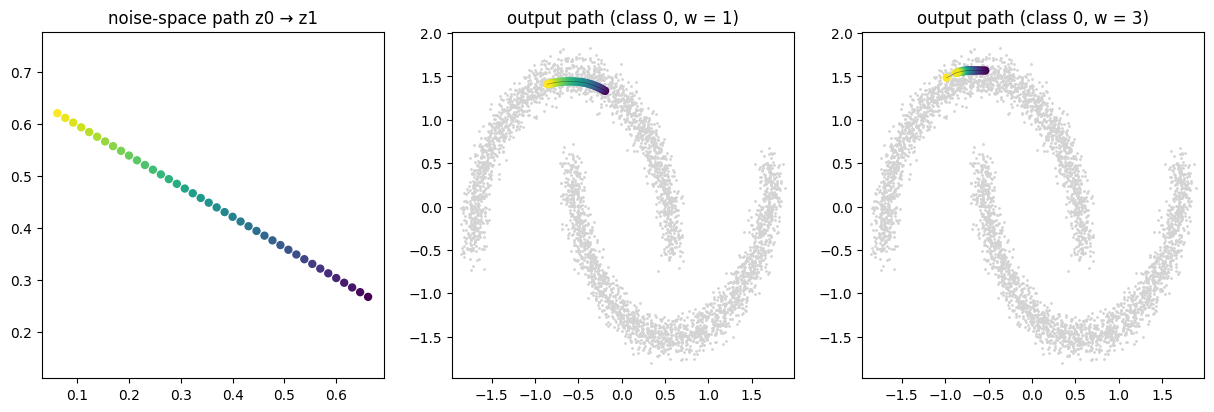

In [26]:
# B3 · Interpolation between two noise seeds (class 0, guided DDIM)
@torch.no_grad()
def guided_sample_from(model, x_init, label, steps=50, w=3.0):
    """Same as guided_sample, but starting from a GIVEN noise tensor x_init (n, 2)."""
    x = x_init.to(device).clone()
    n = x.shape[0]
    c = torch.full((n,), label, dtype=torch.long, device=device)
    null = torch.full((n,), NULL, dtype=torch.long, device=device)
    ts = torch.linspace(T - 1, 0, steps).round().long()
    for i, ti in enumerate(ts):
        t = torch.full((n,), ti, dtype=torch.long, device=device)
        eps_c, eps_u = model(x, t, c), model(x, t, null)
        eps = eps_u + w * (eps_c - eps_u)
        ab_t = abar[ti]; ab_prev = abar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        x0 = ((x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()).clamp(-3, 3)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    return x.cpu()

g = torch.Generator().manual_seed(1)
z0, z1 = torch.randn(1, 2, generator=g), torch.randn(1, 2, generator=g)          # two noise seeds
alphas_i = torch.linspace(0, 1, 40).unsqueeze(1)
z_path = (1 - alphas_i) * z0 + alphas_i * z1                                       # linear interpolation in noise space

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (w, lab) in zip(axes[1:], [(1.0, "w = 1"), (3.0, "w = 3")]):
    path = guided_sample_from(cmodel, z_path, label=0, w=w)
    ax.scatter(X[:, 0], X[:, 1], s=1, c="lightgray")
    sc = ax.scatter(path[:, 0], path[:, 1], c=alphas_i.squeeze(), cmap="viridis", s=25)
    ax.plot(path[:, 0], path[:, 1], "k-", lw=0.4, alpha=0.5)
    ax.set_title(f"output path (class 0, {lab})"); ax.axis("equal")
axes[0].scatter(z_path[:, 0], z_path[:, 1], c=alphas_i.squeeze(), cmap="viridis", s=25)
axes[0].set_title("noise-space path z0 → z1"); axes[0].axis("equal")
plt.show()

✏️ **Discussão B3.** As duas sementes ficaram próximas no espaço do ruído (z₀≈(0,65; 0,27) e z₁≈(0,06; 0,62)) e a trajetória de saída é uma curva suave que desliza pelo topo da lua da classe 0, sem sair dela. Isso faz sentido no DDIM, porque o mapa do ruído para os dados é determinístico e contínuo, logo uma reta no ruído dá uma curva contínua de amostras. Com `w=3` o troço percorrido é mais curto e fica concentrado na zona central da lua, o que bate certo com a perda de diversidade da Q4. Para a amostra sair das luas teria de escolher sementes bem afastadas ou um `w` grande: aí a reta passa por regiões que o modelo manda para fora da lua ou para o espaço entre as pontas, e a curva dobra ou salta, porque uma gaussiana (que é toda ligada) tem de ser esticada sobre uma lua fina e curva. Além disso, a interpolação linear de gaussianas reduz a norma (os pontos do meio ficam "menos ruidosos" do que o normal), e é por isso que em imagens se usa a interpolação esférica (slerp).